# 04 Silent distress: do buildings that NYC does not hear from hide danger?

The hypothesis: buildings whose *non-complaint* profile looks bad but whose complaint record is empty ("silent") carry hidden risk. The test: fit a condition model **without complaint information**, flag the top decile of the within-borough gap between predicted condition and complaint volume, and ask whether silent buildings later have *more* serious outcomes than their predicted condition implies, or than matched louder buildings.

If silence hid danger, the observed/predicted ratio would be at or above 1. All source tables are `reports/phase4/*.csv`; the full write-up is [`docs/silent_distress_phase4.md`](../docs/silent_distress_phase4.md).

In [1]:
from nbutil import *
R4 = REPORTS / "phase4"
cg = pd.read_csv(R4 / "calibration_groups.csv")
p = cg[cg.outcome == "primary"].set_index("group")
p[["n_rows", "n_events", "observed", "predicted", "ratio_level_corrected", "ratio_level_corrected_lo", "ratio_level_corrected_hi"]].round(4)

,n_rows,n_events,observed,predicted,ratio_level_corrected,ratio_level_corrected_lo,ratio_level_corrected_hi
group,,,,,,,
all,1614360,8945,0.0055,0.0049,1.0000,1.0000,1.0000
silent,161546,949,0.0059,0.0063,0.8362,0.7581,0.9134
not_silent,1452814,7996,0.0055,0.0048,1.0238,1.0131,1.0346
silent_resid,39839,852,0.0214,0.0271,0.7135,0.6284,0.7898
access_blocked,25009,251,0.0100,0.0082,1.1076,0.9264,1.3092
silent_311,161575,981,0.0061,0.0063,0.8586,0.7813,0.9267
silent_rental_only,146150,728,0.0050,0.0054,0.8279,0.7388,0.9174
p_hat_top_decile,161432,4934,0.0306,0.0285,0.9584,0.9246,0.9892


## 1. Are silent buildings riskier than their predicted condition says?

Primary outcome: a vacate order or a DOB physical-hazard violation in the next 12 months (the least tenant-driven outcome available; chosen after seeing event-rate stability, before any gap result was computed, and disclosed). Ratios are observed / predicted, corrected for the model's overall level.

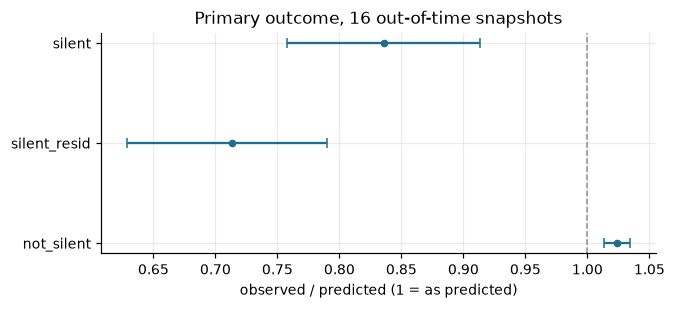

In [2]:
g = p.loc[[i for i in ["silent", "silent_resid", "not_silent"] if i in p.index]]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
forest(ax, list(g.index), g.ratio_level_corrected.tolist(), g.ratio_level_corrected_lo.tolist(), g.ratio_level_corrected_hi.tolist(), xlabel="observed / predicted (1 = as predicted)")
ax.set_title("Primary outcome, 16 out-of-time snapshots"); plt.show()

The silent group sits **below 1**: 16% fewer events than the model expects, not more.

## 2. Matched comparison: silent vs similar buildings with louder records

Coarsened exact matching on predicted condition, borough, size band and year built, ATT weights, cluster bootstrap by building.

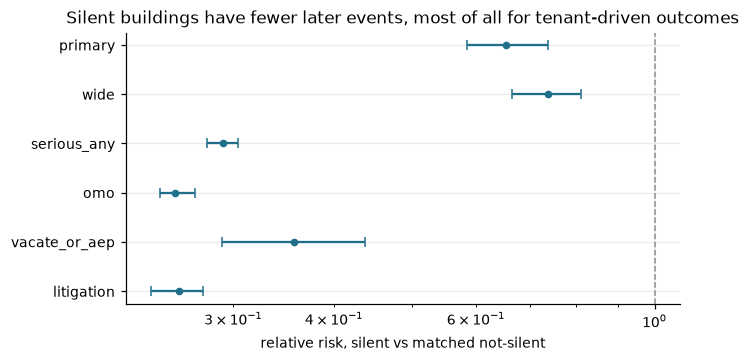

,rate_treated,rate_control,rr,rr_lo,rr_hi,events_treated
outcome,,,,,,
primary,0.006,0.009,0.653,0.586,0.737,937.0
wide,0.012,0.017,0.737,0.665,0.810,1961.0
serious_any,0.039,0.135,0.291,0.279,0.304,6285.0
omo,0.026,0.104,0.254,0.244,0.269,4238.0
vacate_or_aep,0.002,0.006,0.357,0.290,0.437,371.0
litigation,0.015,0.058,0.257,0.237,0.275,2377.0


In [3]:
mt = pd.read_csv(R4 / "matched.csv")
a = mt[(mt.analysis == "matched") & (mt.treatment == "silent") & (mt.subset == "all snapshots")].set_index("outcome")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
forest(ax, list(a.index), a.rr.tolist(), a.rr_lo.tolist(), a.rr_hi.tolist(), xlabel="relative risk, silent vs matched not-silent")
ax.set_xscale("log"); ax.set_title("Silent buildings have fewer later events, most of all for tenant-driven outcomes"); plt.show()
a[["rate_treated", "rate_control", "rr", "rr_lo", "rr_hi", "events_treated"]].round(3)

Chain-driven outcomes (OMO charges, litigation, AEP) show relative risks of 0.25 to 0.36. **That is largely mechanical**: those events begin with a complaint, so they are rare where nobody complains. The primary outcome (0.65) is the least chain-driven and still below 1, but is not independent of the reporting system either.

## 3. Robustness of the primary result

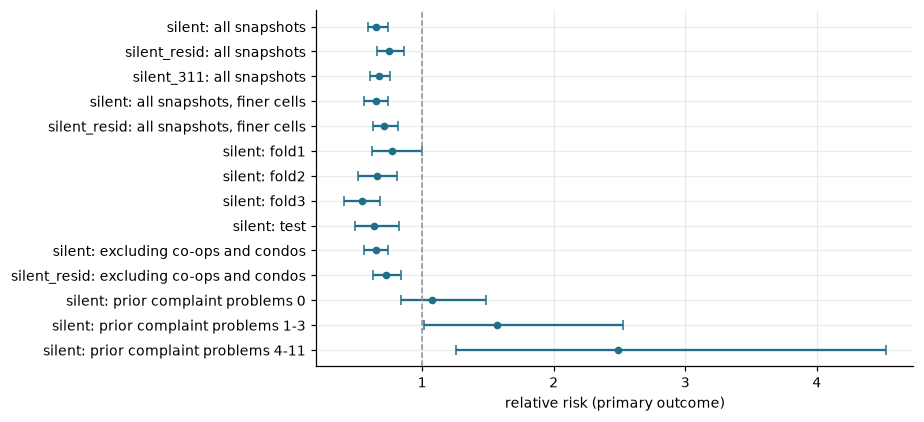

Shuffling the silent flag inside the matching cells gives a ratio near 1 (the real ratios are outside the shuffled range):


,outcome,real_rr,placebo_mean,placebo_lo,placebo_hi,shuffles,real_outside_placebo
0,primary,0.653,1.005,0.928,1.074,200,True
1,wide,0.737,1.002,0.955,1.056,200,True
2,serious_any,0.291,0.999,0.983,1.015,200,True
3,omo,0.254,1.000,0.979,1.021,200,True
4,vacate_or_aep,0.357,0.998,0.909,1.088,200,True
5,litigation,0.257,0.997,0.970,1.023,200,True


In [4]:
b = mt[(mt.outcome == "primary") & (mt.treatment.isin(["silent", "silent_resid", "silent_311"]))].copy()
b["label"] = b.treatment + ": " + b.subset
fig, ax = plt.subplots(figsize=(7, 4.2))
forest(ax, b.label.tolist(), b.rr.tolist(), b.rr_lo.tolist(), b.rr_hi.tolist(), xlabel="relative risk (primary outcome)")
plt.show()
pl = pd.read_csv(R4 / "placebo.csv")
print("Shuffling the silent flag inside the matching cells gives a ratio near 1 (the real ratios are outside the shuffled range):")
pl.round(3)

In [5]:
pd.read_csv(R4 / "adjusted.csv").query("flag == 'silent'").round(3)

,flag,outcome,rr,rr_lo,rr_hi,rows
0,silent,primary,0.790,0.701,0.892,1614360
1,silent,wide,0.823,0.752,0.900,1614360
2,silent,serious_any,0.378,0.362,0.396,1614360
3,silent,omo,0.334,0.316,0.353,1614360


Same sign in all four out-of-time folds, in rental-only buildings, with finer cells, with 311 instead of HPD complaints, and with the model-residual definition of silence. The shuffle gives 1.00. Covariate adjustment moves it from 0.65 to 0.79: still below 1.

## 4. The milder version that survives: condition still predicts later complaints among the complaint-free

In [6]:
lr = pd.read_csv(R4 / "later_loudness_regression.csv")
lr[["sample", "term", "irr", "irr_lo", "irr_hi"]].round(2)

,sample,term,irr,irr_lo,irr_hi
0,all buildings in the test slice,"predicted condition (p_hat), per +1 SD of logit",1.63,1.58,1.67
1,all buildings in the test slice,log(1 + prior-12m complaint problems),2.17,2.14,2.21
2,buildings with zero complaint problems in the ...,"predicted condition (p_hat), per +1 SD of logit",1.70,1.65,1.76


Among buildings with **no complaint at all** in the prior year, the non-complaint condition score still predicts complaints in the next year (incidence rate ratio 1.70 per standard deviation). But compared with matched buildings that had the same prior complaint level, silent buildings are *not* louder later (0.96), so the rise is what regression to the mean predicts. Suppression and noise cannot be told apart.

## 5. Access-blocked buildings

At least 3 closed problems and at least half closed for no access (9.8% of eligible buildings).

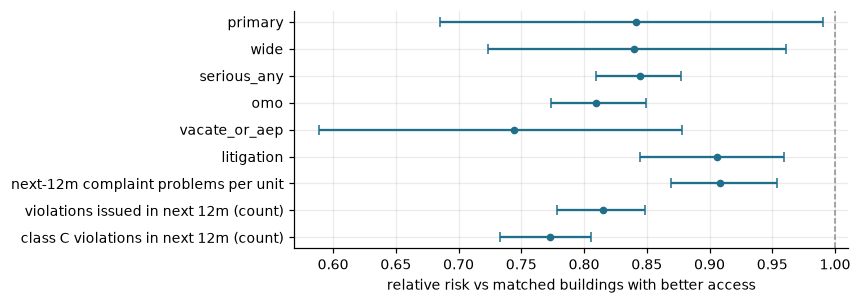

In [7]:
ab = pd.read_csv(R4 / "access_blocked.csv")
ab = ab[ab.analysis == "access_blocked"]
x = ab[ab.subset.str.startswith("eligible")].set_index("outcome")
fig, ax = plt.subplots(figsize=(6.5, 2.8))
forest(ax, list(x.index), x.rr.tolist(), x.rr_lo.tolist(), x.rr_hi.tolist(), xlabel="relative risk vs matched buildings with better access")
plt.show()

The no-access mechanism is real (about 16% of closed problems) but access-blocked buildings show **no hidden extra risk**: fewer later events (0.84) and fewer later violations (0.81), which is also what the chain predicts when a closure stops a violation from being written.

## 6. Who is in the silent group? (fairness)

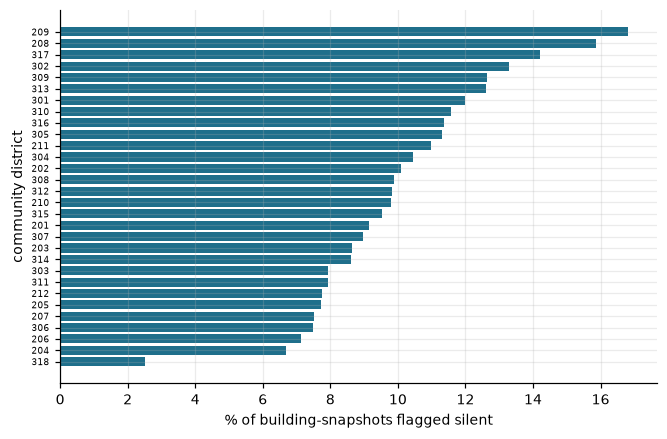

,borough,units_flagged,units_other,zero_complaints_flagged,zero_complaints_other,coop_condo_flagged,coop_condo_other
0,BK,23.99,8.80,0.99,0.80,0.10,0.09
3,BX,50.34,18.00,0.97,0.58,0.08,0.03
6,all,29.97,10.89,0.99,0.75,0.10,0.08


In [8]:
geo = pd.read_csv(R4 / "geography.csv")
cd = geo[geo.level == "community_district"].sort_values("silent_share")
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(cd.area.astype(str), 100 * cd.silent_share, color=BLUE); ax.set_xlabel("% of building-snapshots flagged silent"); ax.set_ylabel("community district"); ax.tick_params(axis="y", labelsize=6)
plt.show()
comp = pd.read_csv(R4 / "composition.csv")
comp[comp.flag == "silent"][["borough", "units_flagged", "units_other", "zero_complaints_flagged", "zero_complaints_other", "coop_condo_flagged", "coop_condo_other"]].round(2)

The flag is 10% of every borough by construction. Silent buildings are mostly **large, complaint-free buildings** (about 30 units vs 11). Reading "silent" as "disadvantaged" or "neglected" is not supported: they do not have worse outcomes and no demographic data were used. The scores are research estimates, not findings about any owner or tenant.

## Verdict
- Silent-distress in its **strong form is not supported**: silent buildings have an ordinary event rate for their size.
- A **milder form is weakly supported**: condition predicts later complaints among the complaint-free, though regression to the mean explains the rise.
- **Mostly, silence reflects ordinary risk.** 77% of building-snapshots have no complaint in a year.

![matched forest](../reports/phase4/figures/matched_forest.png)
